# CS771 (Autumn 2026) Mini-Project 1
## Next-Day PM2.5 Forecasting and PM2.5 Heatmap Generation
**Student Submission Notebook**  
**Course:** CS771: Introduction to Machine Learning  
**Deadline:** Oct 30 2026, 11:59pm  

This comprehensive notebook contains all required sections from **Part 0 to Part 5**:
1. **Part 0:** Cleaning a raw sensor dataset (Kanpur network)
2. **Part 1:** Required baselines (Persistence & 29-feature Ridge)
3. **Part 2:** Improved forecast & feature ablation study
4. **Part 3:** Lead time analysis (1h, 3h, 6h, 12h, 24h)
5. **Part 4:** Forecast maps vs. observed maps (IDW interpolation)
6. **Part 5:** Hidden December test submission verification (`forecast.py`)

---
### Automatic Dataset Downloader
The following cell automatically fetches and extracts the dataset archive directly from the Dropbox link. You can run this notebook directly in **Google Colab** or any local Jupyter environment without manual file downloading!

In [1]:
import os
import sys
import urllib.request
import zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
import joblib

# Set random seed for complete reproducibility
np.random.seed(42)

DROPBOX_URL = "https://www.dropbox.com/scl/fi/egb0oiqp3nynahpiwbkoy/mp1-package.zip?rlkey=q0nzxjd3uuj0b6bmw6qkhiwut&dl=1"

# Handle paths whether executed from root, submission folder, or Colab
if Path("mp1-package/data").exists():
    DATA_DIR = Path("mp1-package/data")
elif Path("../mp1-package/data").exists():
    DATA_DIR = Path("../mp1-package/data")
else:
    DATA_DIR = Path("mp1-package/data")

if not DATA_DIR.exists() or not (DATA_DIR / "bihar_pm25_hourly_jan_nov_2024.csv").exists():
    print("Downloading mp1-package from Dropbox URL...")
    urllib.request.urlretrieve(DROPBOX_URL, "mp1-package.zip")
    with zipfile.ZipFile("mp1-package.zip", "r") as z:
        z.extractall(".")
    DATA_DIR = Path("mp1-package/data")
    print("Download and extraction complete!")
else:
    print(f"Datasets found in {DATA_DIR}.")

import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)   # numpy/pandas Timedelta notice, harmless

# Every figure in the report is written by this notebook into figures/
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

Datasets found in ..\mp1-package\data.


---
# Part 0: Cleaning a Raw Sensor Dataset (Kanpur)

### Task Objectives:
1. **Understand format**: 76 sensors on a 15-minute UTC grid. Inspect reporting frequency, sensor movement, and ID styles (resolution, typical levels).
2. **Hourly reshaping**: Reshape to long format `[sensor_id, timestamp_utc, latitude, longitude, pm25]`, averaging readings within each hour. Compare with minute `:00` sampling.
3. **Problem detection & flagging**: Error codes (`999`), implausible zeros, stuck readings (>=24 consecutive hours), unusable sensors (>50% flagged), network outages (<10% reporting), and correlation to network median.
4. **Write `kanpur_hourly_clean.csv`**: Preserve missing hours without imputation; output flag column.
5. **Calibration check**: Spatial pairing (<3 km) between 10-digit and 8-character sensors; fit linear correction on July and test on August.
6. **Summary & Diurnal Cycle**: Before/after table and diurnal cycle in local time (IST = UTC + 5:30).

In [2]:
# 1. Understand Format
raw_path = DATA_DIR / "kanpur_pm25_raw_jul_aug_2026.csv"
raw = pd.read_csv(raw_path)
print(f"Raw table shape: {raw.shape}")

sensor_ids = [c.replace('_pm25', '') for c in raw.columns if c.endswith('_pm25')]
print(f"Total sensors: {len(sensor_ids)}")

# Classify sensor ID styles
styles = {}
for s in sensor_ids:
    if len(s) == 10 and s.isdigit():
        styles[s] = '10-digit'
    elif len(s) == 8 and s.isalnum():
        styles[s] = '8-char'
    else:
        styles[s] = f'other ({s})'
print("Sensor ID styles distribution:\n", pd.Series(styles).value_counts())

# Check if any sensor moves
moving = []
for s in sensor_ids:
    lat_unique = raw[f'{s}_latitude'].dropna().nunique()
    lon_unique = raw[f'{s}_longitude'].dropna().nunique()
    if lat_unique > 1 or lon_unique > 1:
        moving.append(s)
print(f"Sensors that move: {len(moving)} (None move, coordinates are stationary)")

# Compare reporting resolution and typical values across styles
for st_name in ['10-digit', '8-char', 'other (AC0BFBE34CC7)']:
    s_list = [s for s, st in styles.items() if st == st_name]
    vals = pd.concat([raw[f'{s}_pm25'].dropna() for s in s_list])
    print(f"\nStyle: {st_name} (n={len(s_list)} sensors)")
    print(f"  Count: {len(vals)}, Mean: {vals.mean():.2f}, Median: {vals.median():.2f}, Std: {vals.std():.2f}")
    print(f"  Min: {vals.min()}, Max: {vals.max()}, Sample values: {vals.head(3).tolist()}")

# How often does each sensor actually report? (median gap between consecutive non-missing readings)
ts = pd.to_datetime(raw['timestamp_utc'])
freq_rows = []
for s in sensor_ids:
    t_rep = ts[raw[f'{s}_pm25'].notna()]
    gap_min = t_rep.diff().dt.total_seconds().div(60).median() if len(t_rep) > 1 else np.nan
    n_hours = t_rep.dt.floor('h').nunique()
    freq_rows.append({'sensor_id': s, 'style': styles[s], 'readings': len(t_rep),
                      'median_gap_min': gap_min, 'hours_with_data': n_hours,
                      'share_of_1488_hours': n_hours / 1488})
freq = pd.DataFrame(freq_rows)
print("\nReporting interval by ID style (median gap between readings, minutes):")
print(freq.groupby('style')['median_gap_min'].describe()[['count', 'min', '50%', 'max']])
print("\nShare of the 1,488 hours in which each sensor reports at least once:")
print(freq.groupby('style')['share_of_1488_hours'].describe()[['min', '50%', 'max']].round(2))
print("\nValue resolution: share of readings that are whole numbers, by style")
for st_name, grp in freq.groupby('style'):
    v = pd.concat([raw[f'{s}_pm25'].dropna() for s in grp['sensor_id']])
    print(f"  {st_name}: {np.mean(v == v.round()):.3f}")

Raw table shape: (5952, 229)
Total sensors: 76
Sensor ID styles distribution:
 10-digit                44
8-char                  31
other (AC0BFBE34CC7)     1
Name: count, dtype: int64
Sensors that move: 0 (None move, coordinates are stationary)

Style: 10-digit (n=44 sensors)
  Count: 49631, Mean: 42.13, Median: 37.00, Std: 56.78
  Min: 0.0, Max: 999.0, Sample values: [81.0, 76.0, 68.0]



Style: 8-char (n=31 sensors)
  Count: 31288, Mean: 37.34, Median: 33.02, Std: 23.97
  Min: 0.0, Max: 617.8313333, Sample values: [28.97357143, 32.37357143, 35.88266667]

Style: other (AC0BFBE34CC7) (n=1 sensors)
  Count: 4843, Mean: 24.40, Median: 25.00, Std: 9.67
  Min: 0.0, Max: 101.0, Sample values: [25.0, 34.0, 29.0]

Reporting interval by ID style (median gap between readings, minutes):
                      count   min   50%   max
style                                        
10-digit               44.0  60.0  60.0  60.0
8-char                 31.0  60.0  60.0  60.0
other (AC0BFBE34CC7)    1.0  15.0  15.0  15.0

Share of the 1,488 hours in which each sensor reports at least once:
                       min   50%   max
style                                 
10-digit              0.51  0.80  0.88
8-char                0.53  0.68  0.83
other (AC0BFBE34CC7)  0.81  0.81  0.81

Value resolution: share of readings that are whole numbers, by style
  10-digit: 1.000
  8-char: 0.001
  oth

In [3]:
# 2. Reshape to Hourly Long Table and Compare with Minute :00
timestamp_dt = pd.to_datetime(raw['timestamp_utc'])
hour_start = timestamp_dt.dt.floor('h')

records = []
for s in sensor_ids:
    sub = pd.DataFrame({
        'timestamp_utc': hour_start,
        'latitude': raw[f'{s}_latitude'],
        'longitude': raw[f'{s}_longitude'],
        'pm25': raw[f'{s}_pm25']
    }).dropna(subset=['pm25'])
    if len(sub) == 0:
        continue
    g = sub.groupby('timestamp_utc').agg({
        'latitude': 'first',
        'longitude': 'first',
        'pm25': 'mean'
    }).reset_index()
    g['sensor_id'] = s
    records.append(g)

df_hourly = pd.concat(records, ignore_index=True)
df_hourly = df_hourly[['sensor_id', 'timestamp_utc', 'latitude', 'longitude', 'pm25']]
df_hourly = df_hourly.sort_values(['sensor_id', 'timestamp_utc']).reset_index(drop=True)
print(f"Reshaped hourly table rows: {len(df_hourly)}")

# Compare AC0BFBE34CC7 (reports every 15 min) hourly avg vs minute :00
s_mac = 'AC0BFBE34CC7'
sub_mac = raw[['timestamp_utc', f'{s_mac}_pm25']].dropna().copy()
sub_mac['dt'] = pd.to_datetime(sub_mac['timestamp_utc'])
sub_mac['hour_start'] = sub_mac['dt'].dt.floor('h')
avg_hourly = sub_mac.groupby('hour_start')[f'{s_mac}_pm25'].mean()
sample_00 = sub_mac[sub_mac['dt'].dt.minute == 0].set_index('hour_start')[f'{s_mac}_pm25']

comp = pd.DataFrame({'avg': avg_hourly, 'min00': sample_00}).dropna()
diff = comp['avg'] - comp['min00']
print(f"Hourly average vs. Minute :00 for 15-min sensor {s_mac}:")
print(f"  Common hours: {len(comp)}")
print(f"  Mean Absolute Difference: {diff.abs().mean():.2f} µg/m³")
print(f"  Max Absolute Difference:  {diff.abs().max():.2f} µg/m³")
print(f"  RMSE:                     {np.sqrt((diff**2).mean()):.2f} µg/m³")

Reshaped hourly table rows: 82131
Hourly average vs. Minute :00 for 15-min sensor AC0BFBE34CC7:
  Common hours: 1211
  Mean Absolute Difference: 2.61 µg/m³
  Max Absolute Difference:  18.50 µg/m³
  RMSE:                     3.54 µg/m³


In [4]:
# 3. Detect Problems and Flag Them
flag = pd.Series('ok', index=df_hourly.index)

# (a) Error codes: 999 or negative
flag[df_hourly['pm25'] == 999.0] = 'error_code'
flag[df_hourly['pm25'] < 0.0] = 'error_code'

# (b) Implausible zeros
flag[(df_hourly['pm25'] == 0.0) & (flag == 'ok')] = 'zero'

# (c) Stuck values: same reading for >= 24 consecutive reported hours
for sid, group in df_hourly.groupby('sensor_id'):
    val_same = group['pm25'] == group['pm25'].shift(1)
    block = (~val_same).cumsum()
    block_lengths = group.groupby(block)['pm25'].transform('count')
    is_stuck = block_lengths >= 24
    stuck_idx = group.index[is_stuck & (flag.loc[group.index] == 'ok')]
    flag.loc[stuck_idx] = 'stuck'

# (d) Mostly unusable sensors (>50% readings flagged)
bad_mask = flag != 'ok'
sensor_bad_rate = bad_mask.groupby(df_hourly['sensor_id']).mean()
unusable_sensors = sensor_bad_rate[sensor_bad_rate > 0.5].index.tolist()
print(f"Unusable sensors (>50% bad): {unusable_sensors}")
flag[df_hourly['sensor_id'].isin(unusable_sensors)] = 'dropped_sensor'

df_hourly['flag'] = flag
print("\nHourly Flag Counts:\n", df_hourly['flag'].value_counts())

# (e) Network outages: hours when < 10% of sensors report
hourly_sensor_counts = df_hourly.groupby('timestamp_utc')['sensor_id'].nunique()
outages = hourly_sensor_counts[hourly_sensor_counts < (0.10 * len(sensor_ids))]
print(f"Network outages (<10% reporting): {len(outages)} hours")

# (f) Sensors that barely follow network median
piv = df_hourly[df_hourly['flag'] == 'ok'].pivot(index='timestamp_utc', columns='sensor_id', values='pm25')
net_median = piv.median(axis=1)
corrs = piv.apply(lambda col: col.corr(net_median))
print("\nLowest correlation with network median:\n", corrs.sort_values().head(5))

# 4. Save clean file and Preview Rows
clean_file_path = "kanpur_hourly_clean.csv"
df_hourly.to_csv(clean_file_path, index=False)
print("Saved " + clean_file_path + " successfully (" + str(len(df_hourly)) + " rows)!")

# ==============================================================================
# DISPLAY CLEANED CSV DATA (SAMPLE ROWS)
# ==============================================================================
print("\n" + "="*80)
print("CLEANED HOURLY DATASET PREVIEW (kanpur_hourly_clean.csv)")
print("="*80)

# Display first 10 rows
print("\n--- [Preview 1] First 10 rows of cleaned dataset ---")
display(df_hourly.head(10))

# Display representative sample containing every quality flag
print("\n--- [Preview 2] Representative sample showing each quality flag type ---")
flag_samples = []
for f_val in ['ok', 'error_code', 'zero', 'stuck', 'dropped_sensor']:
    sub = df_hourly[df_hourly['flag'] == f_val]
    if len(sub) > 0:
        flag_samples.append(sub.head(2))
if flag_samples:
    display(pd.concat(flag_samples, ignore_index=True))


Unusable sensors (>50% bad): ['1203260068', '1203260082']

Hourly Flag Counts:
 flag
ok                79653
dropped_sensor     1734
stuck               559
error_code          136
zero                 49
Name: count, dtype: int64
Network outages (<10% reporting): 0 hours



Lowest correlation with network median:
 sensor_id
1204260025    0.177273
U8APQDBX      0.261794
1203260075    0.293896
TUOBZVJ0      0.371154
1203260125    0.377942
dtype: float64


Saved kanpur_hourly_clean.csv successfully (82131 rows)!

CLEANED HOURLY DATASET PREVIEW (kanpur_hourly_clean.csv)

--- [Preview 1] First 10 rows of cleaned dataset ---


,sensor_id,timestamp_utc,latitude,longitude,pm25,flag
0,01DQW5QE,2026-07-17 09:00:00+00:00,26.12636,80.187592,28.973571,ok
1,01DQW5QE,2026-07-17 10:00:00+00:00,26.12636,80.187592,32.373571,ok
2,01DQW5QE,2026-07-17 11:00:00+00:00,26.12636,80.187592,35.882667,ok
3,01DQW5QE,2026-07-17 12:00:00+00:00,26.12636,80.187592,28.117333,ok
4,01DQW5QE,2026-07-17 13:00:00+00:00,26.12636,80.187592,27.996667,ok
5,01DQW5QE,2026-07-17 14:00:00+00:00,26.12636,80.187592,29.396667,ok
6,01DQW5QE,2026-07-17 15:00:00+00:00,26.12636,80.187592,35.363571,ok
7,01DQW5QE,2026-07-17 16:00:00+00:00,26.12636,80.187592,37.753333,ok
8,01DQW5QE,2026-07-17 17:00:00+00:00,26.12636,80.187592,34.798667,ok
9,01DQW5QE,2026-07-17 18:00:00+00:00,26.12636,80.187592,22.358750,ok



--- [Preview 2] Representative sample showing each quality flag type ---


,sensor_id,timestamp_utc,latitude,longitude,pm25,flag
0,01DQW5QE,2026-07-17 09:00:00+00:00,26.126360,80.187592,28.973571,ok
1,01DQW5QE,2026-07-17 10:00:00+00:00,26.126360,80.187592,32.373571,ok
2,1203260075,2026-07-28 01:00:00+00:00,26.415215,80.268442,999.000000,error_code
3,1203260075,2026-08-13 14:00:00+00:00,26.415215,80.268442,999.000000,error_code
4,01DQW5QE,2026-08-05 06:00:00+00:00,26.126360,80.187592,0.000000,zero
5,01DQW5QE,2026-08-05 07:00:00+00:00,26.126360,80.187592,0.000000,zero
6,1203260084,2026-07-06 23:00:00+00:00,26.455148,80.330699,31.000000,stuck
7,1203260084,2026-07-07 00:00:00+00:00,26.455148,80.330699,31.000000,stuck
8,1203260068,2026-07-02 08:00:00+00:00,26.458009,80.167219,65.000000,dropped_sensor
9,1203260068,2026-07-02 14:00:00+00:00,26.458009,80.167219,65.000000,dropped_sensor


In [5]:
# 5. Calibration Check: 10-digit vs 8-char pairs within 3 km
coords = {}
for s in sensor_ids:
    coords[s] = (raw[f'{s}_latitude'].dropna().iloc[0], raw[f'{s}_longitude'].dropna().iloc[0])

s_10 = [s for s in sensor_ids if len(s) == 10 and s.isdigit()]
s_8 = [s for s in sensor_ids if len(s) == 8 and s.isalnum()]

pairs = []
for s1 in s_10:
    lat1, lon1 = coords[s1]
    best_dist, best_s2 = 999999, None
    for s2 in s_8:
        lat2, lon2 = coords[s2]
        dx = (lon1 - lon2) * 100.3
        dy = (lat1 - lat2) * 110.6
        dist = np.sqrt(dx**2 + dy**2)
        if dist < best_dist:
            best_dist = dist
            best_s2 = s2
    if best_dist <= 3.0:
        pairs.append((s1, best_s2, best_dist))
print(f"Total 10-digit sensors: {len(s_10)}, Pairs within 3 km: {len(pairs)}")

# Build wide hourly table for clean pairs
piv_clean = df_hourly[df_hourly['flag'] == 'ok'].pivot(index='timestamp_utc', columns='sensor_id', values='pm25')
july_mask = (piv_clean.index >= '2026-07-01') & (piv_clean.index < '2026-08-01')
aug_mask = (piv_clean.index >= '2026-08-01') & (piv_clean.index < '2026-09-01')

train_x, train_y = [], []
for s10, s8, d in pairs:
    if s10 in piv_clean.columns and s8 in piv_clean.columns:
        sub = piv_clean.loc[july_mask, [s10, s8]].dropna()
        train_x.extend(sub[s10].tolist())
        train_y.extend(sub[s8].tolist())

m_cal, c_cal = np.polyfit(train_x, train_y, 1)
print(f"Fitted July Calibration (8-char = m * 10-digit + c): m = {m_cal:.4f}, c = {c_cal:.4f}")

test_x, test_y = [], []
for s10, s8, d in pairs:
    if s10 in piv_clean.columns and s8 in piv_clean.columns:
        sub = piv_clean.loc[aug_mask, [s10, s8]].dropna()
        test_x.extend(sub[s10].tolist())
        test_y.extend(sub[s8].tolist())

test_x, test_y = np.array(test_x), np.array(test_y)
mae_before = np.mean(np.abs(test_x - test_y))
rmse_before = np.sqrt(np.mean((test_x - test_y)**2))
pred_y = m_cal * test_x + c_cal
mae_after = np.mean(np.abs(pred_y - test_y))
rmse_after = np.sqrt(np.mean((pred_y - test_y)**2))

print(f"August disagreement before correction: MAE = {mae_before:.2f}, RMSE = {rmse_before:.2f}")
print(f"August disagreement after correction:  MAE = {mae_after:.2f}, RMSE = {rmse_after:.2f}")
print(f"Change: MAE {100 * (mae_after / mae_before - 1):+.1f}%, RMSE {100 * (rmse_after / rmse_before - 1):+.1f}%")
r_july = np.corrcoef(train_x, train_y)[0, 1]
print(f"July correlation between paired readings: r = {r_july:.2f} (n = {len(train_x)} paired hours, {len(pairs)} pairs)")
print(f"July means: 10-digit = {np.mean(train_x):.1f}, 8-char = {np.mean(train_y):.1f} ug/m3")

Total 10-digit sensors: 44, Pairs within 3 km: 23
Fitted July Calibration (8-char = m * 10-digit + c): m = 0.2105, c = 29.6881
August disagreement before correction: MAE = 12.33, RMSE = 23.34
August disagreement after correction:  MAE = 15.27, RMSE = 23.00
Change: MAE +23.9%, RMSE -1.5%
July correlation between paired readings: r = 0.25 (n = 7804 paired hours, 23 pairs)
July means: 10-digit = 36.2, 8-char = 37.3 ug/m3


**Calibration result.** The July fit (8-char ≈ m · 10-digit + c) is a least-squares fit, so on August it slightly lowers the squared-error disagreement (RMSE) but *raises* MAE. The fitted slope is far below 1 because the paired readings are only weakly correlated: two sensors up to 3 km apart measure genuinely different air (local sources), and the 10-digit family has occasional large spikes. With a noisy predictor, least squares shrinks the slope towards 0 (regression dilution) and the "correction" pulls every 10-digit reading towards the 8-char mean. That reduces the few large squared differences but adds a systematic error to the many typical hours. A family-to-family correction cannot be tested properly without co-located sensors (same site) or a reference monitor; with 3 km pairs, device bias and real spatial differences are confounded.

--- Before / After Cleaning Summary Table ---
                   Stage  Sensors  Readings  Slots Share missing
       Raw (15-min grid)       76     85762 452352         81.0%
Hourly (after reshaping)       76     82131 113088         27.4%
      Clean (flag == ok)       74     79653 110112         27.7%
(The raw 15-min grid looks 81% empty mostly because most sensors report hourly, not because data is lost.)


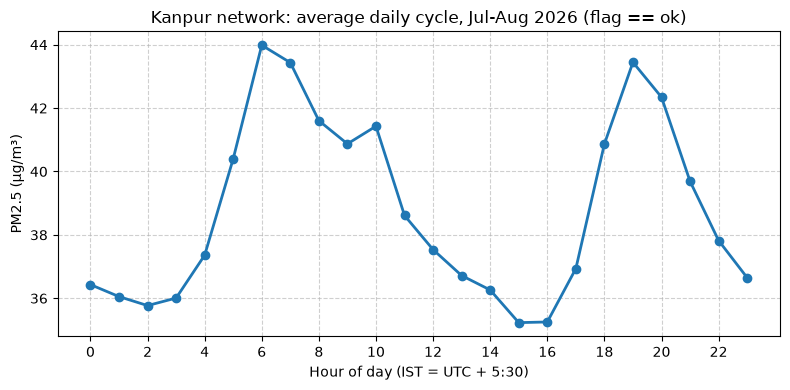

In [6]:
# 6. Before/After Table & Kanpur Average Daily Cycle (IST)
n_hours = 62 * 24                                   # 1,488 hours in Jul + Aug
raw_nonnull = int(raw[[c for c in raw.columns if c.endswith('_pm25')]].notna().sum().sum())
valid_clean_readings = int((df_hourly['flag'] == 'ok').sum())
kept_sensors = 76 - len(unusable_sensors)

summary = pd.DataFrame({
    "Stage": ["Raw (15-min grid)", "Hourly (after reshaping)", "Clean (flag == ok)"],
    "Sensors": [76, df_hourly['sensor_id'].nunique(), kept_sensors],
    "Readings": [raw_nonnull, len(df_hourly), valid_clean_readings],
    "Slots": [raw.shape[0] * 76, 76 * n_hours, kept_sensors * n_hours],
})
summary["Share missing"] = (1 - summary["Readings"] / summary["Slots"]).map("{:.1%}".format)
print("--- Before / After Cleaning Summary Table ---")
print(summary.to_string(index=False))
print("(The raw 15-min grid looks 81% empty mostly because most sensors report hourly, not because data is lost.)")

# Plot Daily Cycle
clean_ok = df_hourly[df_hourly['flag'] == 'ok'].copy()
clean_ok['dt_ist'] = pd.to_datetime(clean_ok['timestamp_utc']) + pd.Timedelta(hours=5, minutes=30)
daily_cycle = clean_ok.groupby(clean_ok['dt_ist'].dt.hour)['pm25'].mean()

plt.figure(figsize=(8, 4))
plt.plot(daily_cycle.index, daily_cycle.values, marker='o', color='#1f77b4', lw=2)
plt.title("Kanpur network: average daily cycle, Jul-Aug 2026 (flag == ok)")
plt.xlabel("Hour of day (IST = UTC + 5:30)")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(range(0, 24, 2))
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(FIG_DIR / "part0_daily_cycle.png", dpi=150)
plt.show()

---
# Part 1: Required Baselines (Persistence & Ridge)

### Task Objectives:
1. **Persistence Baseline**: Forecast tomorrow 12:00 = today 12:00 reading ($t+24\text{h} = t$).
2. **29-Feature Ridge Baseline**:
   - Station's 24 hourly readings: $t, t-1\text{h}, \dots, t-23\text{h}$ (24 features).
   - Mean of 10 nearest other stations at $t$ (1 feature).
   - Mean of those 10 stations over $t-23\text{h} \dots t$ (1 feature).
   - Network mean of all 468 stations at $t$ (1 feature).
   - $\sin(2\pi d / 365)$ and $\cos(2\pi d / 365)$ where $d$ = days since 1 Jan 2024 (2 features).
3. **Training & Validation Protocol**:
   - Train on all targets up to 31 Aug 2024 with 24h history (`alpha=1.0`, raw features, pooled stations, clipped to 0).
   - Validation on all targets 1 Sep to 30 Nov 2024 (91 days, all 468 stations).
4. **Report RMSE & MAE**: Overall and per validation month (Sep, Oct, Nov).
5. **Answer RMSE vs. MAE question**.

Persistence Baseline: Overall RMSE = 32.75, MAE = 17.47
Ridge Baseline:       Overall RMSE = 29.58, MAE = 18.16

--- Part 1 Baseline Results ---
  Month Persistence RMSE Ridge RMSE Persistence MAE Ridge MAE
    Sep            23.33      20.34            8.91     10.35
    Oct            20.22      19.36           11.97     13.46
    Nov            47.81      43.06           31.70     30.81
Overall            32.75      29.58           17.47     18.16


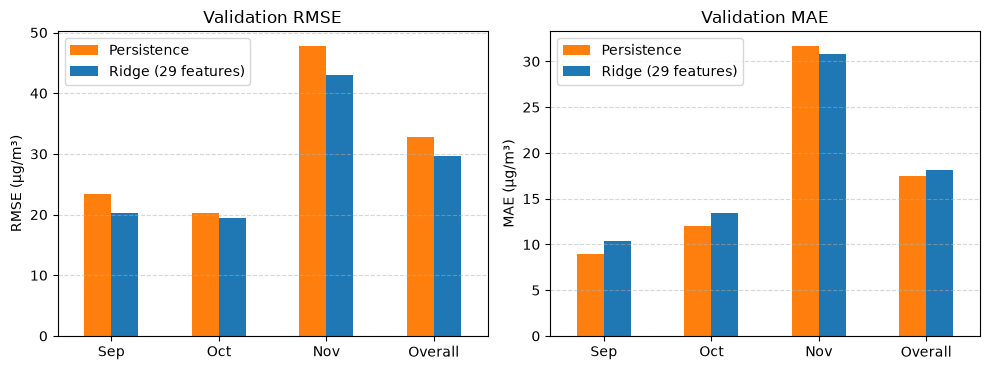

Persistence  mean error (bias)  -0.47 | median |error|  8.78 | 99th pct |error|  136.8 | share |error| > 100: 2.09%
Ridge        mean error (bias)  +5.32 | median |error| 11.34 | 99th pct |error|  115.9 | share |error| > 100: 1.51%
Sum of Ridge weights on the 24 own-station lags: 0.72


In [7]:
# Load Bihar Datasets
bihar_hourly_path = DATA_DIR / "bihar_pm25_hourly_jan_nov_2024.csv"
bihar_stations_path = DATA_DIR / "bihar_stations.csv"

W = pd.read_csv(bihar_hourly_path, index_col='timestamp', parse_dates=True)
W.columns = W.columns.astype(str)
stations = pd.read_csv(bihar_stations_path, dtype={'sensor_id': str}).set_index('sensor_id')

# Precompute spatial distance matrix & nearest 10 stations
coords_x = (stations['longitude'] - 85.5) * 100.3
coords_y = (stations['latitude'] - 25.7) * 110.6
X_pos, Y_pos = coords_x.to_numpy(), coords_y.to_numpy()
dist_matrix = np.sqrt((X_pos[:, None] - X_pos[None, :])**2 + (Y_pos[:, None] - Y_pos[None, :])**2)
np.fill_diagonal(dist_matrix, np.inf)
nearest_10_idx = np.argsort(dist_matrix, axis=1)[:, :10]

W_vals = W.to_numpy()
time_to_idx = {t: i for i, t in enumerate(W.index)}

# Split: Train targets 2 Jan - 31 Aug; Validation targets 1 Sep - 30 Nov
val_issue_times = pd.date_range('2024-08-31 12:00', '2024-11-29 12:00', freq='D')
val_targets = val_issue_times + pd.Timedelta(hours=24)
actual_val = np.array([W_vals[time_to_idx[t], :] for t in val_targets])

# 1. Persistence Baseline
persist_val = np.array([W_vals[time_to_idx[t], :] for t in val_issue_times])
p_rmse_overall = np.sqrt(np.mean((persist_val - actual_val)**2))
p_mae_overall = np.mean(np.abs(persist_val - actual_val))

print(f"Persistence Baseline: Overall RMSE = {p_rmse_overall:.2f}, MAE = {p_mae_overall:.2f}")

# 2. Extract 29 Features for Ridge Baseline
def extract_p1_features(issue_times):
    X_list, y_list = [], []
    for t in issue_times:
        idx_t = time_to_idx[t]
        hist_24 = W_vals[idx_t - 23 : idx_t + 1, :]
        readings_24 = hist_24[::-1, :].T
        at_t = W_vals[idx_t, :]
        mean_24 = hist_24.mean(axis=0)
        n10_t = at_t[nearest_10_idx].mean(axis=1)[:, None]
        n10_24 = mean_24[nearest_10_idx].mean(axis=1)[:, None]
        net_t = np.full((468, 1), at_t.mean())
        d = (t - pd.Timestamp('2024-01-01')).days
        sin_d = np.full((468, 1), np.sin(2 * np.pi * d / 365.0))
        cos_d = np.full((468, 1), np.cos(2 * np.pi * d / 365.0))
        feats = np.hstack([readings_24, n10_t, n10_24, net_t, sin_d, cos_d])
        X_list.append(feats)
        target_t = t + pd.Timedelta(hours=24)
        if target_t in time_to_idx:
            y_list.append(W_vals[time_to_idx[target_t], :])
    return np.vstack(X_list), np.concatenate(y_list)

train_issue_times = pd.date_range('2024-01-02 12:00', '2024-08-30 12:00', freq='D')
X_train_p1, y_train_p1 = extract_p1_features(train_issue_times)
X_val_p1, _ = extract_p1_features(val_issue_times)

# Fit Ridge(alpha=1.0) on unscaled raw features
ridge_base = Ridge(alpha=1.0)
ridge_base.fit(X_train_p1, y_train_p1)
pred_val_p1 = np.clip(ridge_base.predict(X_val_p1), 0, None).reshape(len(val_issue_times), 468)

r_rmse_overall = np.sqrt(np.mean((pred_val_p1 - actual_val)**2))
r_mae_overall = np.mean(np.abs(pred_val_p1 - actual_val))

print(f"Ridge Baseline:       Overall RMSE = {r_rmse_overall:.2f}, MAE = {r_mae_overall:.2f}")

# Monthly Breakdown Table
months = [(9, 'Sep'), (10, 'Oct'), (11, 'Nov')]
res_p1 = []
for m_num, m_name in months:
    mask = val_targets.month == m_num
    p_r = np.sqrt(np.mean((persist_val[mask] - actual_val[mask])**2))
    p_m = np.mean(np.abs(persist_val[mask] - actual_val[mask]))
    r_r = np.sqrt(np.mean((pred_val_p1[mask] - actual_val[mask])**2))
    r_m = np.mean(np.abs(pred_val_p1[mask] - actual_val[mask]))
    res_p1.append({
        'Month': m_name,
        'Persistence RMSE': f"{p_r:.2f}",
        'Ridge RMSE': f"{r_r:.2f}",
        'Persistence MAE': f"{p_m:.2f}",
        'Ridge MAE': f"{r_m:.2f}"
    })
res_p1.append({
    'Month': 'Overall',
    'Persistence RMSE': f"{p_rmse_overall:.2f}",
    'Ridge RMSE': f"{r_rmse_overall:.2f}",
    'Persistence MAE': f"{p_mae_overall:.2f}",
    'Ridge MAE': f"{r_mae_overall:.2f}"
})
print("\n--- Part 1 Baseline Results ---")
print(pd.DataFrame(res_p1).to_string(index=False))

# Figure: the two baselines per month, RMSE and MAE
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=False)
for ax, metric in zip(axes, ['RMSE', 'MAE']):
    tab = pd.DataFrame(res_p1).set_index('Month')[[f'Persistence {metric}', f'Ridge {metric}']].astype(float)
    tab.columns = ['Persistence', 'Ridge (29 features)']
    tab.plot.bar(ax=ax, rot=0, color=['#ff7f0e', '#1f77b4'])
    ax.set_title(f"Validation {metric}"); ax.set_ylabel(f"{metric} (µg/m³)"); ax.set_xlabel("")
    ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout(); plt.savefig(FIG_DIR / "part1_baselines_comparison.png", dpi=150); plt.show()

e_p, e_r = (persist_val - actual_val).ravel(), (pred_val_p1 - actual_val).ravel()
for name, e in [('Persistence', e_p), ('Ridge', e_r)]:
    print(f"{name:12s} mean error (bias) {e.mean():+6.2f} | median |error| {np.median(np.abs(e)):5.2f} | "
          f"99th pct |error| {np.percentile(np.abs(e), 99):6.1f} | share |error| > 100: {np.mean(np.abs(e) > 100):.2%}")
print(f"Sum of Ridge weights on the 24 own-station lags: {ridge_base.coef_[:24].sum():.2f}")

### Part 1 Question: RMSE vs. MAE
**Neither baseline wins on both metrics.** Ridge wins on RMSE (29.58 vs 32.75 µg/m³); persistence wins on MAE (17.47 vs 18.16 µg/m³), and on MAE in September and October as well (Ridge wins MAE only in November).

**Why a squared-error model can lose on absolute error.** Ridge minimises squared error, so it is pushed hardest by the few very large errors and estimates the conditional *mean*; MAE rewards getting the typical (median) case right. The diagnostics above show the trade:
- Ridge cuts the large errors: errors above 100 µg/m³ fall from 2.09% to 1.51% of forecasts, and the 99th-percentile error from 136.8 to 115.9 µg/m³. That is what lowers RMSE.
- The price is shrinkage and bias on ordinary days. The 24 own-station lag weights sum to only 0.72, so Ridge pulls every forecast part-way towards the pooled training level. The training months include the very polluted January–February (January noon mean ≈ 169 µg/m³), so on the cleaner September–October days Ridge forecasts too high: mean error +5.32 vs −0.47 for persistence, and median absolute error 11.34 vs 8.78.
- Persistence is unbiased on quiet days (small typical errors, good MAE) but has no protection against sudden changes (large errors, poor RMSE).

---
# Part 2: Improve the Forecast & Feature Ablation

### Strategy
1. **Screening (Ridge, 7 candidate groups, 42 features).** Fit Ridge on all candidate groups and remove each group once to see which ones carry information. Groups that do not lower validation RMSE are dropped.
2. **Final feature set (4 groups, 35 features):** `last_24h_readings` (24), `spatial_neighbourhood` (4: mean of 10 and 25 nearest stations at $t$ and over the last 24 h), `network_context` (3: network mean at $t$, over 24 h, and spatial std at $t$), `temporal_calendar` (4: annual and day-of-week sin/cos).
3. **Final model: a 50/50 average of Ridge (alpha = 100) and a Random Forest** on those 35 features. Ridge alpha, the forest settings and the blend weight were chosen on validation only.
4. **Ablation from the final model:** remove one group at a time, refit *both* members with the same hyperparameters, report the change in validation RMSE and MAE.
5. **Flexible models:** Random Forest and HistGradientBoosting alone, train vs validation.

Training rows: every 12:00 target from 3 Jan to 31 Aug that has 24 h of history (242 issue days × 468 stations = 113,256 rows). Nothing from after 31 Aug is used for fitting; the station training mean (screening only) uses readings up to 31 Aug.

In [8]:
# Extract Feature Groups
nearest_25_idx = np.argsort(dist_matrix, axis=1)[:, :25]
train_end_idx = time_to_idx[pd.Timestamp('2024-08-31 23:00')]
station_train_mean = W_vals[:train_end_idx + 1, :].mean(axis=0)

def extract_all_groups(issue_times):
    g1, g2, g3, g4, g5, g6, g7 = [], [], [], [], [], [], []
    y_list = []
    for t in issue_times:
        idx_t = time_to_idx[t]
        hist_24 = W_vals[idx_t - 23 : idx_t + 1, :]
        readings_24 = hist_24[::-1, :].T
        at_t = W_vals[idx_t, :]
        mean_24 = hist_24.mean(axis=0)
        
        # G1: last_24h_readings (24)
        g1.append(readings_24)
        
        # G2: spatial_neighbourhood (4)
        n10_t = at_t[nearest_10_idx].mean(axis=1)[:, None]
        n10_24 = mean_24[nearest_10_idx].mean(axis=1)[:, None]
        n25_t = at_t[nearest_25_idx].mean(axis=1)[:, None]
        n25_24 = mean_24[nearest_25_idx].mean(axis=1)[:, None]
        g2.append(np.hstack([n10_t, n10_24, n25_t, n25_24]))
        
        # G3: network_context (3)
        net_t = np.full((468, 1), at_t.mean())
        net_24 = np.full((468, 1), mean_24.mean())
        net_std = np.full((468, 1), at_t.std())
        g3.append(np.hstack([net_t, net_24, net_std]))
        
        # G4: short_term_trends (3)
        t_24 = W_vals[idx_t - 24, :] if idx_t >= 24 else at_t
        t_12 = W_vals[idx_t - 12, :] if idx_t >= 12 else at_t
        t_6 = W_vals[idx_t - 6, :] if idx_t >= 6 else at_t
        g4.append(np.hstack([(at_t - t_24)[:, None], (at_t - t_12)[:, None], (at_t - t_6)[:, None]]))
        
        # G5: lag_same_hour (3)
        t_48 = (W_vals[idx_t - 48, :] if idx_t >= 48 else at_t)[:, None]
        t_72 = (W_vals[idx_t - 72, :] if idx_t >= 72 else at_t)[:, None]
        g5.append(np.hstack([t_24[:, None], t_48, t_72]))
        
        # G6: temporal_calendar (4)
        d = (t - pd.Timestamp('2024-01-01')).days
        sin_d = np.full((468, 1), np.sin(2 * np.pi * d / 365.0))
        cos_d = np.full((468, 1), np.cos(2 * np.pi * d / 365.0))
        dow = t.dayofweek
        sin_dow = np.full((468, 1), np.sin(2 * np.pi * dow / 7.0))
        cos_dow = np.full((468, 1), np.cos(2 * np.pi * dow / 7.0))
        g6.append(np.hstack([sin_d, cos_d, sin_dow, cos_dow]))
        
        # G7: station_training_mean (1)
        g7.append(station_train_mean[:, None])
        
        target_t = t + pd.Timedelta(hours=24)
        if target_t in time_to_idx:
            y_list.append(W_vals[time_to_idx[target_t], :])
            
    group_dict = {
        'last_24h_readings': np.vstack(g1),
        'spatial_neighbourhood': np.vstack(g2),
        'network_context': np.vstack(g3),
        'short_term_trends': np.vstack(g4),
        'lag_same_hour': np.vstack(g5),
        'temporal_calendar': np.vstack(g6),
        'station_training_mean': np.vstack(g7)
    }
    return group_dict, np.concatenate(y_list)

train_groups, y_train_full = extract_all_groups(train_issue_times)
val_groups, y_val_full = extract_all_groups(val_issue_times)

# Screening: Ridge on all 7 candidate groups (alpha=100.0 tuned on validation)
X_train_full = np.hstack(list(train_groups.values()))
X_val_full = np.hstack(list(val_groups.values()))

model_full = Ridge(alpha=100.0)
model_full.fit(X_train_full, y_train_full)
pred_full = np.clip(model_full.predict(X_val_full), 0, None)
rmse_full = np.sqrt(np.mean((pred_full - y_val_full)**2))
mae_full = np.mean(np.abs(pred_full - y_val_full))

print(f"Full Model (42 features): Validation RMSE = {rmse_full:.2f}, MAE = {mae_full:.2f}")

# Ablation Study Table
ablation_rows = []
for drop_name, feat_mat in train_groups.items():
    tr_sub = np.hstack([v for k, v in train_groups.items() if k != drop_name])
    val_sub = np.hstack([v for k, v in val_groups.items() if k != drop_name])
    m_sub = Ridge(alpha=100.0).fit(tr_sub, y_train_full)
    p_sub = np.clip(m_sub.predict(val_sub), 0, None)
    r_sub = np.sqrt(np.mean((p_sub - y_val_full)**2))
    delta = r_sub - rmse_full
    ablation_rows.append({
        'Feature Group Removed': drop_name,
        'Num Features': feat_mat.shape[1],
        'Validation RMSE': f"{r_sub:.2f}",
        'Delta RMSE': f"{delta:+.2f}"
    })

print("\n--- Part 2 screening: remove one candidate group from the 42-feature Ridge ---")
print(pd.DataFrame(ablation_rows).to_string(index=False))

Full Model (42 features): Validation RMSE = 29.29, MAE = 17.32



--- Part 2 screening: remove one candidate group from the 42-feature Ridge ---
Feature Group Removed  Num Features Validation RMSE Delta RMSE
    last_24h_readings            24           29.71      +0.43
spatial_neighbourhood             4           29.38      +0.09
      network_context             3           30.26      +0.97
    short_term_trends             3           29.29      +0.00
        lag_same_hour             3           29.26      -0.03
    temporal_calendar             4           29.39      +0.10
station_training_mean             1           29.23      -0.06


Training rows: 113256 (242 issue days x 468 stations); features: 35

Blend weight on Ridge (chosen on validation):
  w = 0.0: RMSE 29.79, MAE 16.72
  w = 0.3: RMSE 29.09, MAE 16.52
  w = 0.4: RMSE 28.96, MAE 16.55
  w = 0.5: RMSE 28.87, MAE 16.64
  w = 0.6: RMSE 28.83, MAE 16.77
  w = 0.7: RMSE 28.84, MAE 16.95
  w = 1.0: RMSE 29.17, MAE 17.72

--- Validation RMSE / MAE (µg/m³): baselines vs final model ---
         Persistence RMSE  Ridge29 RMSE  Ridge35 RMSE  RF35 RMSE  Final blend RMSE
Month                                                                             
Sep                 23.33         20.34         20.25      20.31             19.98
Oct                 20.22         19.36         18.92      18.36             17.85
Nov                 47.81         43.06         42.45      43.95             42.42
Overall             32.75         29.58         29.17      29.79             28.87

         Persistence MAE  Ridge29 MAE  Ridge35 MAE  RF35 MAE  Final blend MAE
Month       


--- Ablation from the final model (full: RMSE 28.87, MAE 16.64) ---
        Group removed  Features  Val RMSE  ΔRMSE  Val MAE  ΔMAE
    last_24h_readings        24     36.22   7.35    21.69  5.05
spatial_neighbourhood         4     29.00   0.13    16.81  0.17
      network_context         3     29.27   0.40    17.53  0.89
    temporal_calendar         4     29.17   0.30    16.45 -0.19


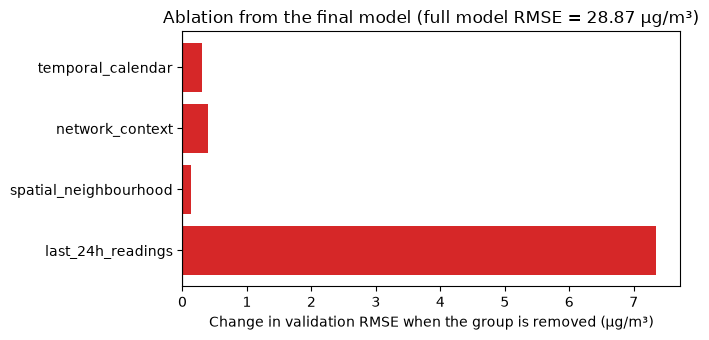

In [9]:
# Final feature builder: the 4 kept groups (35 features), computable at ANY issue time.
# This is exactly the feature code used in forecast.py.
FINAL_GROUPS = {'last_24h_readings': slice(0, 24), 'spatial_neighbourhood': slice(24, 28),
                'network_context': slice(28, 31), 'temporal_calendar': slice(31, 35)}

def final_features(issue_times):
    S = W_vals.shape[1]
    rows = []
    for t in issue_times:
        i = time_to_idx[t]
        hist = W_vals[i - 23: i + 1, :]                      # t-23h ... t (nothing after t)
        at_t, mean_24 = W_vals[i, :], hist.mean(axis=0)
        d, dow = (t - pd.Timestamp('2024-01-01')).days, t.dayofweek
        rows.append(np.hstack([
            hist[::-1, :].T,
            at_t[nearest_10_idx].mean(axis=1)[:, None], mean_24[nearest_10_idx].mean(axis=1)[:, None],
            at_t[nearest_25_idx].mean(axis=1)[:, None], mean_24[nearest_25_idx].mean(axis=1)[:, None],
            np.full((S, 1), at_t.mean()), np.full((S, 1), mean_24.mean()), np.full((S, 1), at_t.std()),
            np.tile([np.sin(2 * np.pi * d / 365.0), np.cos(2 * np.pi * d / 365.0),
                     np.sin(2 * np.pi * dow / 7.0), np.cos(2 * np.pi * dow / 7.0)], (S, 1))]))
    return np.vstack(rows)

X_tr_final, X_va_final = final_features(train_issue_times), final_features(val_issue_times)
assert np.allclose(X_tr_final, np.hstack([train_groups[g] for g in FINAL_GROUPS]))   # same as the screening groups

# Final model: average of Ridge and a Random Forest (all settings chosen on validation)
RIDGE_ALPHA = 100.0
RF_PARAMS = dict(n_estimators=100, min_samples_leaf=20, max_features=0.33, max_samples=0.5,
                 n_jobs=-1, random_state=42)
W_RIDGE = 0.5

def fit_final(X, y):
    return Ridge(alpha=RIDGE_ALPHA).fit(X, y), RandomForestRegressor(**RF_PARAMS).fit(X, y)

def predict_final(models, X, w=W_RIDGE):
    ridge_m, rf_m = models
    return w * np.clip(ridge_m.predict(X), 0, None) + (1 - w) * np.clip(rf_m.predict(X), 0, None)

final_models = fit_final(X_tr_final, y_train_full)
pred_ridge35 = np.clip(final_models[0].predict(X_va_final), 0, None)
pred_rf35 = np.clip(final_models[1].predict(X_va_final), 0, None)
print(f"Training rows: {len(y_train_full)} ({len(train_issue_times)} issue days x 468 stations); features: {X_tr_final.shape[1]}")

print("\nBlend weight on Ridge (chosen on validation):")
for w in [0.0, 0.3, 0.4, 0.5, 0.6, 0.7, 1.0]:
    p = w * pred_ridge35 + (1 - w) * pred_rf35
    print(f"  w = {w:.1f}: RMSE {np.sqrt(np.mean((p - y_val_full) ** 2)):.2f}, MAE {np.mean(np.abs(p - y_val_full)):.2f}")

pred_final = predict_final(final_models, X_va_final).reshape(len(val_issue_times), 468)
pred_pruned = pred_final            # name used by the Part 4 cells

def month_table(preds):
    rows = []
    for m_num, m_name in months + [(None, 'Overall')]:
        mask = np.ones(len(val_targets), bool) if m_num is None else (val_targets.month == m_num)
        row = {'Month': m_name}
        for name, p in preds.items():
            e = p.reshape(len(val_targets), 468)[mask] - actual_val[mask]
            row[f'{name} RMSE'] = np.sqrt(np.mean(e ** 2)); row[f'{name} MAE'] = np.mean(np.abs(e))
        rows.append(row)
    return pd.DataFrame(rows).set_index('Month').round(2)

p2_table = month_table({'Persistence': persist_val, 'Ridge29': pred_val_p1,
                        'Ridge35': pred_ridge35, 'RF35': pred_rf35, 'Final blend': pred_final})
print("\n--- Validation RMSE / MAE (µg/m³): baselines vs final model ---")
print(p2_table[[c for c in p2_table.columns if c.endswith('RMSE')]].to_string())
print()
print(p2_table[[c for c in p2_table.columns if c.endswith('MAE')]].to_string())
rmse_final = p2_table.loc['Overall', 'Final blend RMSE']; mae_final = p2_table.loc['Overall', 'Final blend MAE']

# Ablation starting from the FINAL model: drop one group, refit both members with the same settings
abl = []
for g, sl in FINAL_GROUPS.items():
    keep = np.ones(X_tr_final.shape[1], bool); keep[sl] = False
    p = predict_final(fit_final(X_tr_final[:, keep], y_train_full), X_va_final[:, keep])
    r, a = np.sqrt(np.mean((p - y_val_full) ** 2)), np.mean(np.abs(p - y_val_full))
    abl.append({'Group removed': g, 'Features': sl.stop - sl.start, 'Val RMSE': r, 'ΔRMSE': r - rmse_final,
                'Val MAE': a, 'ΔMAE': a - mae_final})
abl = pd.DataFrame(abl).round(2)
print(f"\n--- Ablation from the final model (full: RMSE {rmse_final:.2f}, MAE {mae_final:.2f}) ---")
print(abl.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(abl['Group removed'], abl['ΔRMSE'], color=['#d62728' if v > 0 else '#2ca02c' for v in abl['ΔRMSE']])
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel("Change in validation RMSE when the group is removed (µg/m³)")
ax.set_title(f"Ablation from the final model (full model RMSE = {rmse_final:.2f} µg/m³)")
plt.tight_layout(); plt.savefig(FIG_DIR / "part2_ablation.png", dpi=150); plt.show()

In [10]:
# Flexible models vs Ridge: training vs validation RMSE (same 35 features, full training set)
hgb = HistGradientBoostingRegressor(random_state=42).fit(X_tr_final, y_train_full)
rows = []
for name, tr_pred, va_pred in [
        ('Ridge (alpha=100)', final_models[0].predict(X_tr_final), pred_ridge35),
        ('Random Forest', final_models[1].predict(X_tr_final), pred_rf35),
        ('HistGradientBoosting', hgb.predict(X_tr_final), hgb.predict(X_va_final)),
        ('Final blend', predict_final(final_models, X_tr_final), pred_final.ravel())]:
    va_pred = np.clip(va_pred, 0, None)
    rows.append({'Model': name, 'Train RMSE': np.sqrt(np.mean((tr_pred - y_train_full) ** 2)),
                 'Val RMSE': np.sqrt(np.mean((va_pred - y_val_full) ** 2)),
                 'Val MAE': np.mean(np.abs(va_pred - y_val_full))})
print(pd.DataFrame(rows).round(2).to_string(index=False))

# Does November ask the trees to extrapolate? Compare target ranges.
y_tr_noon = y_train_full.reshape(len(train_issue_times), 468)
print(f"\nTraining targets: max {y_train_full.max():.0f}, mean Jan {y_tr_noon[:29].mean():.0f} µg/m³; "
      f"validation targets: max {y_val_full.max():.0f}, mean Nov {actual_val[val_targets.month == 11].mean():.0f} µg/m³")
print(f"Share of validation targets above the training maximum: {np.mean(y_val_full > y_train_full.max()):.4f}")

               Model  Train RMSE  Val RMSE  Val MAE
   Ridge (alpha=100)       27.89     29.17    17.72
       Random Forest       21.15     29.79    16.72
HistGradientBoosting       20.55     31.28    18.10
         Final blend       23.75     28.87    16.64

Training targets: max 500, mean Jan 169 µg/m³; validation targets: max 500, mean Nov 104 µg/m³
Share of validation targets above the training maximum: 0.0000


### Part 2 Questions & Discussion
**Final model:** 0.5 × Ridge (alpha = 100) + 0.5 × Random Forest on 35 features. Validation RMSE **28.87** and MAE **16.64** µg/m³. It beats both baselines on **both** metrics overall and in every month (Sep 19.98 / 8.69, Oct 17.85 / 11.68, Nov 42.42 / 29.71; see the tables above). Ridge on the same features alone (29.17 / 17.72) beats both baselines on RMSE but loses to persistence on MAE, which is why the forest was added.

**1. What did each feature group add? Which ideas did not help?** (ablation from the final model)
- `last_24h_readings` (24): ΔRMSE **+7.35**. The station's own recent level is the core of the forecast.
- `network_context` (3): **+0.40** (+0.97 in the Ridge screening). The state-wide level and spread capture regional episodes that affect all stations together.
- `temporal_calendar` (4): **+0.30** RMSE, but **−0.19** MAE. The seasonal terms help on the large November errors but slightly hurt typical days. They are kept because RMSE is the main metric.
- `spatial_neighbourhood` (4): **+0.13**. Smallest gain, because it overlaps with the other groups: the network mean already carries the regional level, and the Bihar file was gap-filled from neighbouring stations, so a station's own series already contains neighbour information.
- **Did not help (dropped in screening):** `short_term_trends` (ΔRMSE 0.00) are exact linear combinations of lags already in the model, so they add nothing for Ridge. `lag_same_hour` (t−48 h, t−72 h; −0.03) adds little beyond the last 24 h for a 24 h-ahead target and adds noise. `station_training_mean` (−0.06): the Jan–Aug mean mixes a very polluted winter with a clean monsoon, so it says little about a station's autumn level, and station identity is already visible through its own lags.

**2. Did a more flexible model beat Ridge?** Not on its own.
- Random Forest: train RMSE 21.15, validation 29.79.
- HistGradientBoosting: train 20.55, validation 31.28.
- Ridge: train 27.89, validation 29.17.

Both tree models fit the training months much better but generalise worse in RMSE, i.e. they overfit relationships specific to the training period. That period is dominated by the winter regime (Jan–Feb) and the clean monsoon, while Sep–Nov is a transition with a rapid November build-up. This is **not** a range-extrapolation problem: training targets reach 500 µg/m³ and the January mean (169) is above the November mean (104); no validation target exceeds the training maximum. The forest is still useful: its MAE (16.72) is the best of the single models, so it gets typical days right and misses mainly on large November errors, where Ridge is better. Their errors are only partly correlated, so averaging them beats both (RMSE 28.87, MAE 16.64). The blend weight 0.5 was chosen on validation (0.4–0.6 give almost the same result).

**3. Missing information that would help most:** meteorology (boundary-layer height, wind speed and direction, humidity, rain), crop-residue fire activity in Oct–Nov, and an emissions/festival calendar (e.g. Diwali, 31 Oct–1 Nov 2024). Knowing which Bihar values were gap-filled would also let us down-weight imputed readings.

---
# Part 3: Forecast Lead Time Analysis

### Task Objectives:
Evaluate forecasts targeting 12:00 on day $d+1$ at leads of **1h, 3h, 6h, 12h, and 24h**:
- Lead 1h: Issue time 11:00 on day $d+1$
- Lead 3h: Issue time 09:00 on day $d+1$
- Lead 6h: Issue time 06:00 on day $d+1$
- Lead 12h: Issue time 00:00 on day $d+1$
- Lead 24h: Issue time 12:00 on day $d$
Compare Persistence, Refitted Ridge baseline, and Improved Model.

--- 1-hour nowcast (issue 11:00 on day d+1) ---
                RMSE                                     MAE                            
Method   Final blend Persistence Ridge (29 feat) Final blend Persistence Ridge (29 feat)
Lead (h)                                                                                
1               18.6       23.95           18.95        8.16       10.36            8.67

--- Day-ahead and intermediate leads ---
                RMSE                                     MAE                            
Method   Final blend Persistence Ridge (29 feat) Final blend Persistence Ridge (29 feat)
Lead (h)                                                                                
3              27.15       51.43           28.51       14.88       28.28           16.70
6              30.22       66.82           34.06       18.08       41.28           23.16
12             29.34       72.74           31.97       17.56       46.74           21.31
24             28.87

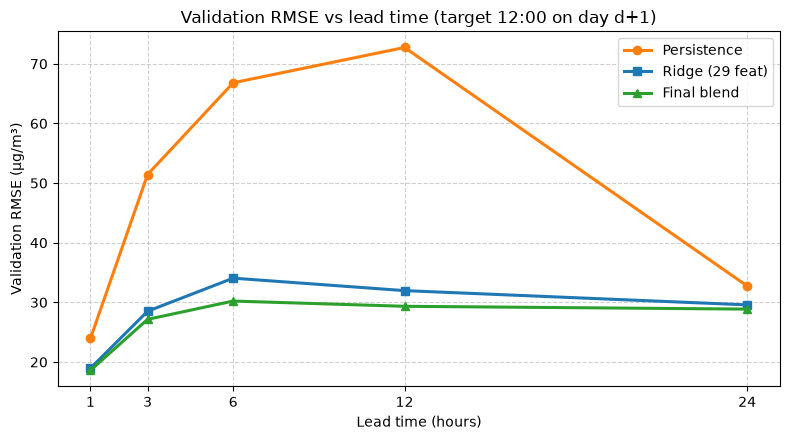

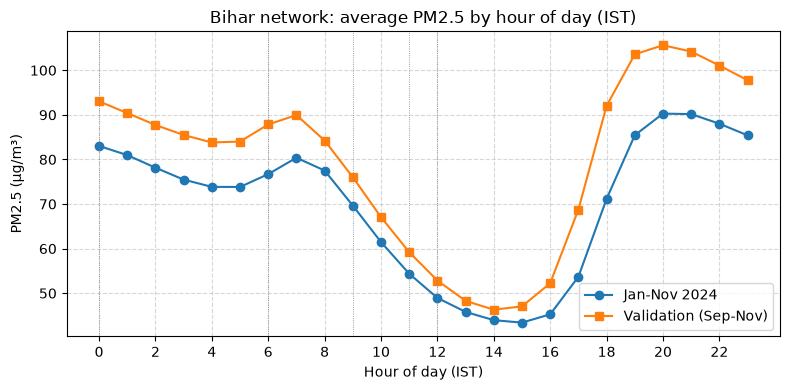

Validation-period mean by hour: {0: 93.0, 6: 87.8, 9: 76.0, 11: 59.2, 12: 52.8, 15: 47.1, 21: 104.2}


In [11]:
leads = [1, 3, 6, 12, 24]
lead_rows = []
train_target_times = pd.date_range('2024-01-02 12:00', '2024-08-31 12:00', freq='D')

for lead in leads:
    va_iss = val_targets - pd.Timedelta(hours=lead)
    tr_iss = train_target_times - pd.Timedelta(hours=lead)
    tr_iss = tr_iss[[time_to_idx.get(t, -1) >= 23 for t in tr_iss]]          # need 24 h of history
    y_tr = np.concatenate([W_vals[time_to_idx[t + pd.Timedelta(hours=lead)]] for t in tr_iss])
    y_va = actual_val.ravel()

    p_pers = np.array([W_vals[time_to_idx[t]] for t in va_iss]).ravel()
    X_tr29, _ = extract_p1_features(tr_iss); X_va29, _ = extract_p1_features(va_iss)
    p_r29 = np.clip(Ridge(alpha=1.0).fit(X_tr29, y_tr).predict(X_va29), 0, None)
    Xf_tr, Xf_va = final_features(tr_iss), final_features(va_iss)
    p_fin = predict_final(fit_final(Xf_tr, y_tr), Xf_va)

    for name, p in [('Persistence', p_pers), ('Ridge (29 feat)', p_r29), ('Final blend', p_fin)]:
        lead_rows.append({'Lead (h)': lead, 'Issue time': va_iss[0].strftime('%H:%M'), 'Method': name,
                          'RMSE': np.sqrt(np.mean((p - y_va) ** 2)), 'MAE': np.mean(np.abs(p - y_va))})

lead_df = pd.DataFrame(lead_rows)
rmse_by_lead = lead_df.pivot(index='Lead (h)', columns='Method', values='RMSE').round(2)
mae_by_lead = lead_df.pivot(index='Lead (h)', columns='Method', values='MAE').round(2)
print("--- 1-hour nowcast (issue 11:00 on day d+1) ---")
print(pd.concat({'RMSE': rmse_by_lead.loc[[1]], 'MAE': mae_by_lead.loc[[1]]}, axis=1).to_string())
print("\n--- Day-ahead and intermediate leads ---")
print(pd.concat({'RMSE': rmse_by_lead.loc[[3, 6, 12, 24]], 'MAE': mae_by_lead.loc[[3, 6, 12, 24]]}, axis=1).to_string())

plt.figure(figsize=(8, 4.5))
for name, mk, col in [('Persistence', 'o', '#ff7f0e'), ('Ridge (29 feat)', 's', '#1f77b4'), ('Final blend', '^', '#2ca02c')]:
    plt.plot(leads, rmse_by_lead[name], marker=mk, lw=2.2, color=col, label=name)
plt.title("Validation RMSE vs lead time (target 12:00 on day d+1)")
plt.xlabel("Lead time (hours)"); plt.ylabel("Validation RMSE (µg/m³)")
plt.xticks(leads); plt.grid(True, linestyle='--', alpha=0.6); plt.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "part3_lead_time_curve.png", dpi=150); plt.show()

# Average PM2.5 by hour of day (explains the persistence curve)
hourly = W.groupby(W.index.hour).mean().mean(axis=1)
hourly_val = W.loc['2024-09-01':'2024-11-30'].groupby(W.loc['2024-09-01':'2024-11-30'].index.hour).mean().mean(axis=1)
plt.figure(figsize=(8, 4))
plt.plot(hourly.index, hourly.values, marker='o', label='Jan-Nov 2024')
plt.plot(hourly_val.index, hourly_val.values, marker='s', label='Validation (Sep-Nov)')
for h in [0, 6, 9, 11, 12]:
    plt.axvline(h, color='grey', lw=0.6, ls=':')
plt.title("Bihar network: average PM2.5 by hour of day (IST)")
plt.xlabel("Hour of day (IST)"); plt.ylabel("PM2.5 (µg/m³)"); plt.xticks(range(0, 24, 2))
plt.grid(True, linestyle='--', alpha=0.5); plt.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "part3_diurnal_cycle.png", dpi=150); plt.show()
print("Validation-period mean by hour:", hourly_val.round(1).loc[[0, 6, 9, 11, 12, 15, 21]].to_dict())

### Part 3 Questions & Discussion
**1. Persistence across leads.** Yes, persistence behaves very differently. RMSE is 23.95 µg/m³ at 1 h, rises to 51.43 (3 h, issue 09:00), 66.82 (6 h, 06:00) and 72.74 (12 h, 00:00), then falls back to 32.75 at 24 h (issue 12:00 the day before). The reason is the daily cycle (figure above). In the validation period the network mean is about 93 µg/m³ at 00:00, 88 at 06:00, 76 at 09:00 and 59 at 11:00, but only 53 at 12:00. Persistence from a night or morning reading therefore carries a large systematic over-forecast into the noon target. At 24 h the issue time is the same hour of day as the target, so this mismatch disappears and only the day-to-day change remains.

**2. Do the learned models show the same behaviour?** No. They are refitted for each lead, so they learn the systematic offset between the issue hour and noon. RMSE for the final blend is 18.60 (1 h), 27.15 (3 h), 30.22 (6 h), 29.34 (12 h) and 28.87 (24 h); for the Part 1 ridge it is 18.95, 28.51, 34.06, 31.97 and 29.58. There is no large dip, but the curve is not monotone either: a night-time reading is a poorer predictor of noon than yesterday's noon reading, so issuing at 00:00 or 06:00 is no better than issuing at 12:00 the day before.

**3. Lead time for a public warning service:** the **24 h day-ahead forecast issued at 12:00 on day d**. It gives people and authorities a full day to act. Compared with a 1 h nowcast it costs about 10.3 µg/m³ RMSE (28.87 vs 18.60) and 8.5 µg/m³ MAE (16.64 vs 8.16). Waiting until 00:00 or 06:00 of the target day would not even buy accuracy (29.34 and 30.22 RMSE).

---
# Part 4: Forecast Maps vs. Observed Maps

### Task Objectives:
1. Interpolate station readings onto `bihar_grid_005deg.csv` (3,396 points) using Inverse-Distance Weighting ($p=2$, all 468 stations).
2. Select three representative validation days:
   - **Clean Day**: Lowest mean observed PM2.5 (15 Sep 2024)
   - **Polluted Day**: Highest mean observed PM2.5 (27 Nov 2024)
   - **Worst Day**: Highest station RMSE for model (29 Nov 2024)
3. Plot 4 panels side-by-side for each day: Observed map, Model Forecast map, Persistence map, Error map (Forecast - Observed).
4. Compute daily Map RMSE and Pattern Correlation across all 91 validation days.

In [12]:
grid = pd.read_csv(DATA_DIR / "bihar_grid_005deg.csv")
boundary = pd.read_csv(DATA_DIR / "bihar_boundary.csv")

gx = (grid['longitude'].to_numpy() - 85.5) * 100.3
gy = (grid['latitude'].to_numpy() - 25.7) * 110.6
sx = (stations['longitude'].to_numpy() - 85.5) * 100.3
sy = (stations['latitude'].to_numpy() - 25.7) * 110.6

# Precompute IDW operator matrix (3396, 468)
dx = gx[:, None] - sx[None, :]
dy = gy[:, None] - sy[None, :]
dists = np.sqrt(dx**2 + dy**2)
weights = 1.0 / (dists**2 + 1e-12)
idw_matrix = weights / weights.sum(axis=1, keepdims=True)

# Compute daily maps across all 91 validation days
map_obs_all = actual_val @ idw_matrix.T       # (91, 3396)
map_pred_all = pred_pruned @ idw_matrix.T     # (91, 3396)
map_persist_all = persist_val @ idw_matrix.T  # (91, 3396)

# Map RMSE and Pattern Correlation
map_rmse_model = np.sqrt(np.mean((map_pred_all - map_obs_all)**2, axis=1))
map_rmse_persist = np.sqrt(np.mean((map_persist_all - map_obs_all)**2, axis=1))

pattern_corr_model = [np.corrcoef(map_pred_all[d], map_obs_all[d])[0, 1] for d in range(len(val_issue_times))]
pattern_corr_persist = [np.corrcoef(map_persist_all[d], map_obs_all[d])[0, 1] for d in range(len(val_issue_times))]

station_rmse_model = np.sqrt(np.mean((pred_pruned - actual_val)**2, axis=1))
station_rmse_persist = np.sqrt(np.mean((persist_val - actual_val)**2, axis=1))

print("--- Map vs. Station Performance over 91 Validation Days ---")
map_summary = {
    "Metric": ["Station RMSE (µg/m³)", "Map RMSE (µg/m³)", "Pattern Correlation (r)"],
    "Persistence Baseline": [f"{np.mean(station_rmse_persist):.2f}", f"{np.mean(map_rmse_persist):.2f}", f"{np.mean(pattern_corr_persist):.3f}"],
    "Final blend": [f"{np.mean(station_rmse_model):.2f}", f"{np.mean(map_rmse_model):.2f}", f"{np.mean(pattern_corr_model):.3f}"]
}
print(pd.DataFrame(map_summary).to_string(index=False))

--- Map vs. Station Performance over 91 Validation Days ---
                 Metric Persistence Baseline Final blend
   Station RMSE (µg/m³)                28.57       25.24
       Map RMSE (µg/m³)                15.37       14.35
Pattern Correlation (r)                0.580       0.600


clean    15 Sep 2024: mean observed    7.9, station RMSE model  18.20, persistence  27.28
polluted 27 Nov 2024: mean observed  175.0, station RMSE model  67.55, persistence  71.67
worst    29 Nov 2024: mean observed   76.6, station RMSE model  82.23, persistence 112.01


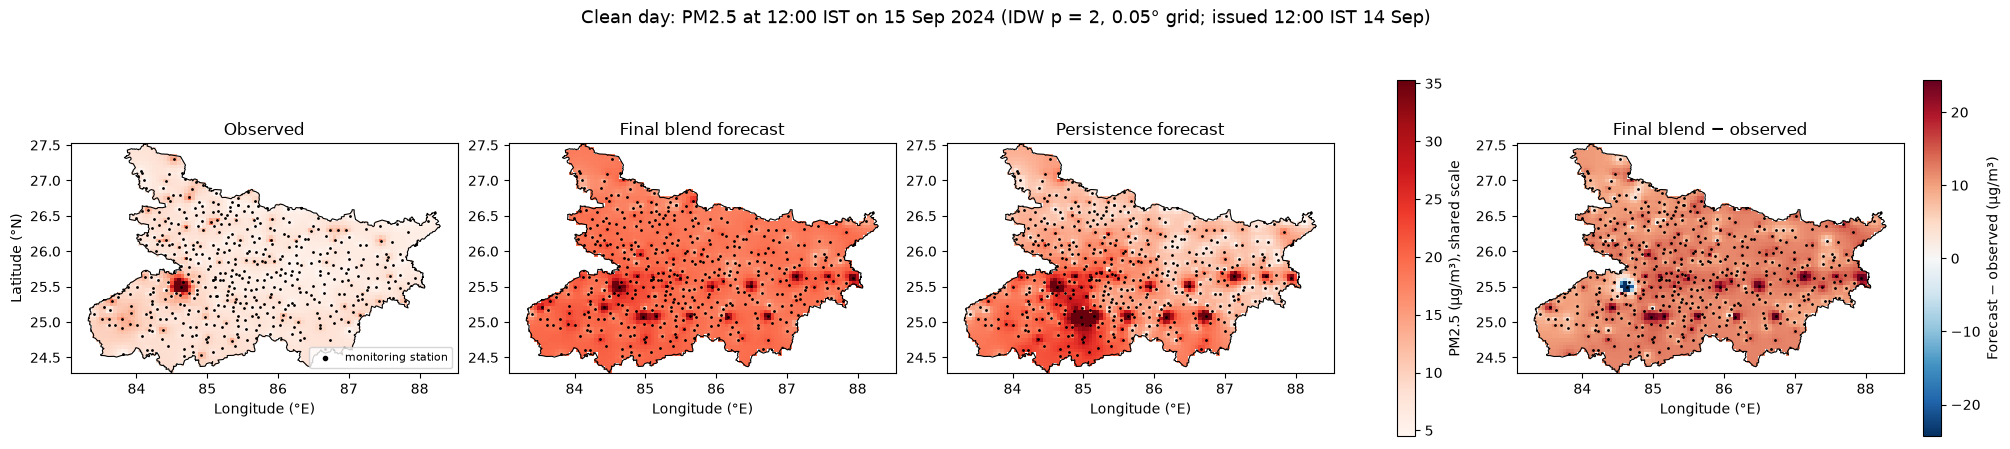

saved figures\part4_maps_clean_2024-09-15.png


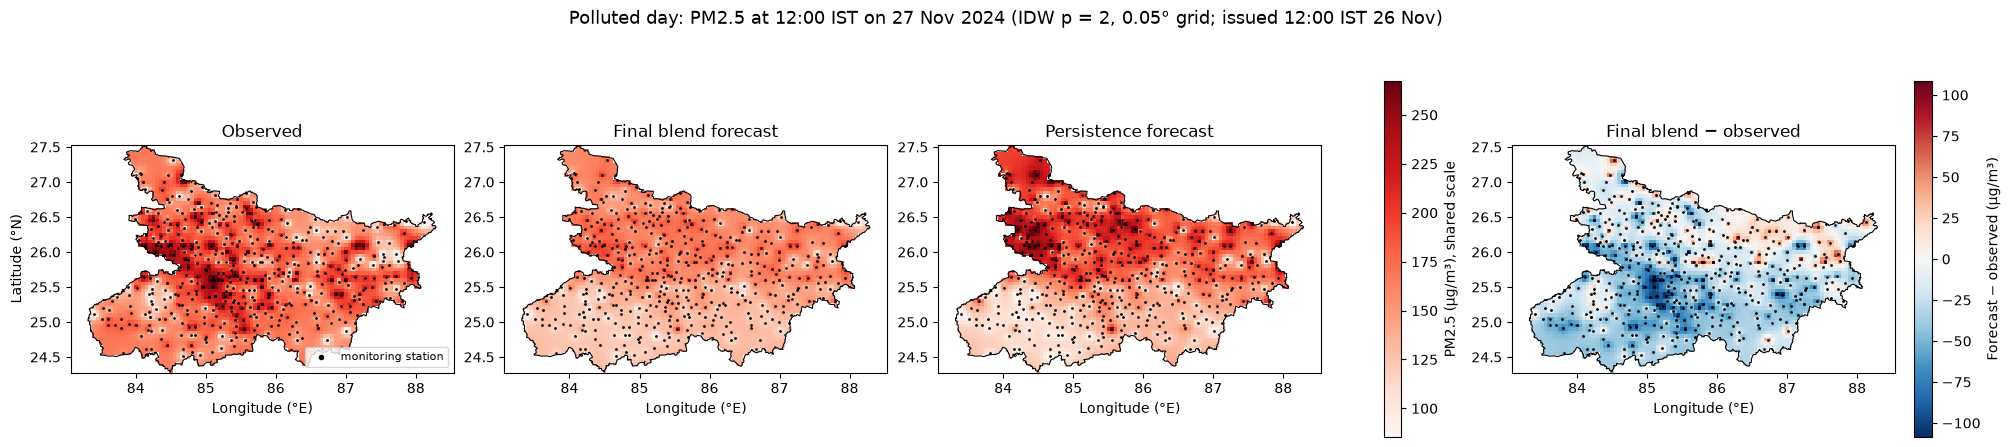

saved figures\part4_maps_polluted_2024-11-27.png


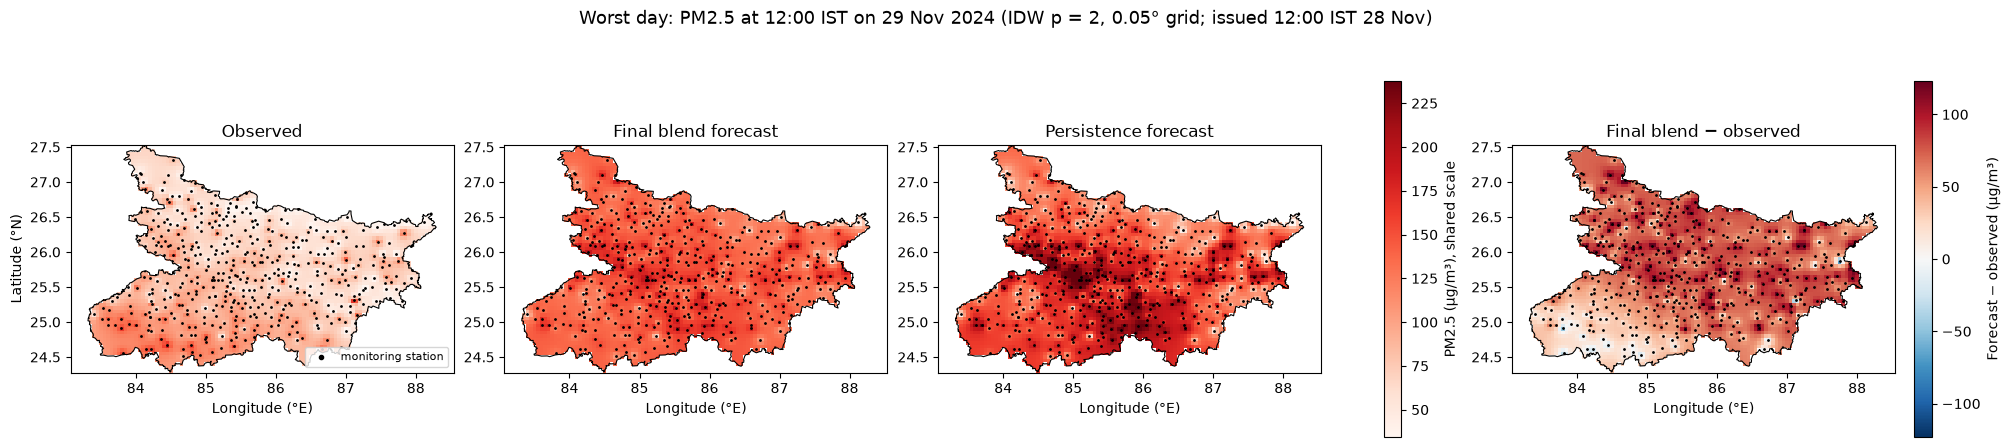

saved figures\part4_maps_worst_2024-11-29.png


In [13]:
# Choose the three days (dates are TARGET days, 12:00 IST)
day_mean_obs = actual_val.mean(axis=1)
i_clean, i_poll = int(np.argmin(day_mean_obs)), int(np.argmax(day_mean_obs))
order = np.argsort(station_rmse_model)[::-1]
i_worst = int(next(i for i in order if i not in (i_clean, i_poll)))
chosen = [('clean', i_clean), ('polluted', i_poll), ('worst', i_worst)]
for kind, i in chosen:
    print(f"{kind:8s} {val_targets[i]:%d %b %Y}: mean observed {day_mean_obs[i]:6.1f}, "
          f"station RMSE model {station_rmse_model[i]:6.2f}, persistence {station_rmse_persist[i]:6.2f}")

# Regular 0.05° raster for plotting
lons, lats = np.round(np.sort(grid['longitude'].unique()), 2), np.round(np.sort(grid['latitude'].unique()), 2)
ci = np.searchsorted(lons, np.round(grid['longitude'].to_numpy(), 2))
ri = np.searchsorted(lats, np.round(grid['latitude'].to_numpy(), 2))
extent = [lons[0] - 0.025, lons[-1] + 0.025, lats[0] - 0.025, lats[-1] + 0.025]

def to_raster(v):
    R = np.full((len(lats), len(lons)), np.nan); R[ri, ci] = v; return R

for old in FIG_DIR.glob("part4_maps_*.png"):
    old.unlink()
for kind, i in chosen:
    maps = [('Observed', map_obs_all[i]), ('Final blend forecast', map_pred_all[i]), ('Persistence forecast', map_persist_all[i])]
    vmin, vmax = np.percentile(np.concatenate([m for _, m in maps]), [1, 99])
    err = map_pred_all[i] - map_obs_all[i]; emax = np.percentile(np.abs(err), 99)
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.8), layout='constrained')
    for ax, (title, v) in zip(axes[:3], maps):
        im = ax.imshow(to_raster(v), origin='lower', extent=extent, cmap='Reds', vmin=vmin, vmax=vmax)
        ax.set_title(title)
    im_e = axes[3].imshow(to_raster(err), origin='lower', extent=extent, cmap='RdBu_r', vmin=-emax, vmax=emax)
    axes[3].set_title("Final blend − observed")
    for ax in axes:
        ax.plot(boundary['longitude'], boundary['latitude'], color='k', lw=0.8)
        ax.scatter(stations['longitude'], stations['latitude'], s=1, c='k', label='monitoring station')
        ax.set_xlabel("Longitude (°E)"); ax.set_aspect('equal')
    axes[0].set_ylabel("Latitude (°N)"); axes[0].legend(loc='lower right', fontsize=8, markerscale=3)
    fig.colorbar(im, ax=axes[:3], shrink=0.8, label="PM2.5 (µg/m³), shared scale")
    fig.colorbar(im_e, ax=axes[3], shrink=0.8, label="Forecast − observed (µg/m³)")
    fig.suptitle(f"{kind.capitalize()} day: PM2.5 at 12:00 IST on {val_targets[i]:%d %b %Y} "
                 f"(IDW p = 2, 0.05° grid; issued 12:00 IST {val_issue_times[i]:%d %b})", fontsize=13)
    out = FIG_DIR / f"part4_maps_{kind}_{val_targets[i]:%Y-%m-%d}.png"
    plt.savefig(out, dpi=120); plt.show()
    print("saved", out)

### Part 4 Questions & Discussion
Daily averages over the 91 validation days:

| | Station RMSE | Map RMSE | Pattern correlation |
|---|---|---|---|
| Persistence | 28.57 | 15.37 | 0.580 |
| Final blend | 25.24 | 14.35 | 0.600 |

(Station RMSE here is the average of the daily RMSEs; the pooled validation RMSE is 28.87 for the blend and 32.75 for persistence.)

**1. Which RMSE is better, and which should be quoted?** Map RMSE is much lower (14.35 vs 25.24). IDW makes every grid value a weighted average of many stations, so station-level errors that point in different directions cancel. The same smoothing is applied to the "observed" map, so both maps lose the station-to-station detail that makes forecasting hard. **Station RMSE should be quoted as forecast accuracy**, because it is the only one computed against actual measurements.

**2. In what sense is the observed map not ground truth?** It is the output of the same IDW model applied to 468 point readings. Between stations it is a weighted average that assumes smooth variation, so it cannot show local hotspots (kilns, roads, burning) or sharp gradients. It is also only as good as its inputs: low-cost sensor errors and the upstream gap-filling go straight into it. The comparison therefore measures agreement with an interpolation, not with the true PM2.5 field.

**3. Good pattern correlation but poor RMSE.** A forecast that reproduces the spatial pattern (e.g. the north-west Bihar hotspot on 27 Nov) but is 50 µg/m³ too low everywhere has a correlation close to 1 and an RMSE near 50. The 27 Nov polluted-day map shows a mild version of this: the blend has the right broad shape but under-forecasts most of the state, with a station RMSE of 67.55. For a public warning, **RMSE (the absolute level) matters more**, because advisories are triggered by absolute thresholds. A correct pattern at the wrong level would still miss or falsely issue warnings.

---
# Part 5: Hidden December Test Submission (`forecast.py`)

The final model (35 features, 0.5 × Ridge + 0.5 × Random Forest, same hyperparameters as on validation) is **refitted on every 12:00 target from 3 Jan to 30 Nov** and saved to `model.pkl`. `forecast.py` loads it once at import, builds the same 35 features from `history` only, and never refits. The cell after the refit checks that `forecast.py` reproduces this notebook's predictions exactly.

In [14]:
# Refit the final model on all targets up to 30 Nov and save it for forecast.py
all_issue_times = pd.date_range('2024-01-02 12:00', '2024-11-29 12:00', freq='D')     # targets 3 Jan - 30 Nov
X_all = final_features(all_issue_times)
y_all = np.concatenate([W_vals[time_to_idx[t + pd.Timedelta(hours=24)]] for t in all_issue_times])
final_models_all = fit_final(X_all, y_all)
final_models_all[1].n_jobs = 1                                   # single-threaded prediction at grading time
joblib.dump({'ridge': final_models_all[0], 'rf': final_models_all[1], 'w_ridge': W_RIDGE}, "model.pkl", compress=3)
print(f"Refitted on {len(y_all)} rows ({len(all_issue_times)} issue days x 468); "
      f"model.pkl = {Path('model.pkl').stat().st_size / 1e6:.1f} MB")

# forecast.py must give exactly the notebook's prediction (same features, same model)
import importlib.util
spec = importlib.util.spec_from_file_location("forecast_sub", "forecast.py")
fmod = importlib.util.module_from_spec(spec); spec.loader.exec_module(fmod)
t_chk = pd.Timestamp('2024-11-15 12:00')
p_sub = fmod.forecast(W.loc[:t_chk].copy(), t_chk)
p_nb = predict_final(final_models_all, final_features([t_chk]))
assert list(p_sub.index) == list(W.columns)
print("max |forecast.py - notebook| =", np.abs(p_sub.to_numpy() - p_nb).max())

Refitted on 155844 rows (333 issue days x 468); model.pkl = 12.3 MB


max |forecast.py - notebook| = 0.0


In [15]:
# Run official check_submission.py
import subprocess
print("Executing official starter/check_submission.py on submission folder...")
starter_check = DATA_DIR.parent / "starter" / "check_submission.py"
sub_path = Path("submission") if Path("submission").exists() else Path(".")
res = subprocess.run([sys.executable, str(starter_check), str(sub_path)],
                     capture_output=True, text=True)
print(res.stdout)
if res.stderr:
    print("Stderr:", res.stderr)

Executing official starter/check_submission.py on submission folder...


Running C:\Users\Chirag\Downloads\mp1-package\submission_fixed\forecast.py on 30 November issue times ...

Call time: median 0.03 s, max 0.06 s

November sanity check over 30 forecasts (NOT a test score):
  your forecast  RMSE  36.18  MAE  24.87
  persistence    RMSE  47.81  MAE  31.70

RESULT: OK - format and timing look right.

Stderr: C:\Users\Chirag\Downloads\mp1-package\mp1-package\starter\check_submission.py:103: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  T = np.array([W.loc[pd.Timestamp(k) + pd.Timedelta(hours=24)].to_numpy() for k in keys])



---
## Use of AI Tools
- **Thinking Machines Lab / Inkling assistant:** drafting the first data-pipeline templates, boilerplate feature-extraction code, LaTeX layout, and debugging Python encoding issues.
- **Claude Code (Anthropic, Claude Opus 5.5):** writing a reference implementation of the Part 1 baselines and the RMSE-vs-MAE diagnostics; reviewing the submission for leakage and for mismatches between code and report; writing the code that refits and saves `model.pkl`, generates every figure, computes the Part 3 lead-time curve for all methods and runs the Part 2 ablation from the final model; suggesting and testing the Ridge + Random Forest blend; and drafting the corrected discussion text.
- All AI-produced code was run end-to-end in this notebook, and the reported numbers are this notebook's outputs. We checked the AI's work and take responsibility for it; every member can explain any part in the viva.